In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy import stats
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report,
)

from forestgap import with_sparse_proximity

In [3]:
print(os.getcwd())

c:\Users\sofia\Documents\GeneralForestProximities\notebooks


In [6]:
from pathlib import Path
import numpy as np

wafer_dir = Path("../datasets")
train_file = wafer_dir / "wafer_TRAIN"
# test_file = wafer_dir / "wafer_TEST"

def read_ucr_split(file_path: Path):
    data = np.loadtxt(file_path, delimiter=",")
    y = data[:, 0].astype(int)
    X = data[:, 1:].astype(float)
    return X, y

X_train, y_train = read_ucr_split(train_file)
# X_test, y_test = read_ucr_split(test_file)

print("Train:", X_train.shape, y_train.shape)
# print("Test:", X_test.shape, y_test.shape)

Train: (1000, 152) (1000,)


In [7]:
X_train

array([[-1.6023 , -1.6708 , -1.6937 , ..., -1.1454 , -1.1454 , -1.1454 ],
       [ 1.0846 ,  1.0846 ,  1.0846 , ...,  1.0653 ,  1.0653 ,  1.0653 ],
       [ 0.36269,  0.36269,  0.36269, ...,  0.39332,  0.39332,  0.39332],
       ...,
       [-0.83289, -0.97729, -0.92342, ..., -0.95368, -0.92342, -0.97729],
       [ 0.93039,  0.93039,  0.93039, ...,  0.93039,  0.93039,  0.93039],
       [-1.1482 , -1.1503 , -1.1482 , ..., -1.1805 , -1.1826 , -1.1848 ]],
      shape=(1000, 152))

In [ ]:
152/8

19.0

In [8]:
X_0_int = np.reshape(X_train[0, :], (19, 8))
X_0_int.sort(axis=1)

In [9]:
ProxIsoForest = with_sparse_proximity(IsolationForest)

model = ProxIsoForest(
    n_estimators=200,
    contamination='auto',
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
    prox_method='oob',
    max_features=5,
 )

model.fit(X_0_int)
print('Model fitted.')

Model fitted.


In [11]:
model.get_proximities().toarray()

array([[1.        , 0.03955696, 0.        , 0.        , 0.2016129 ,
        0.40760866, 0.04280822, 0.        , 0.        , 0.        ,
        0.0529661 , 0.        , 0.03360215, 0.        , 0.        ,
        0.        , 0.24350649, 0.5597015 , 0.38580242],
       [0.03955696, 1.        , 0.40184852, 0.29980013, 0.48999593,
        0.29352412, 0.        , 0.        , 0.03778575, 0.        ,
        0.        , 0.        , 0.        , 0.07233273, 0.03835826,
        0.        , 0.13151406, 0.07557151, 0.06250977],
       [0.        , 0.40184852, 1.        , 0.8771931 , 0.25601637,
        0.        , 0.        , 0.        , 0.        , 0.05473454,
        0.        , 0.        , 0.        , 0.13605443, 0.        ,
        0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.29980013, 0.8771931 , 1.        , 0.08488964,
        0.        , 0.        , 0.        , 0.        , 0.04537205,
        0.        , 0.        , 0.        , 0.11278196, 0.        ,
        0.   

In [ ]:
model.predict(X_0_int)



array([-1, -1, -1, -1, -1, -1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1, -1,
       -1, -1])

In [ ]:
dec = model.decision_function(X_0_int)

In [ ]:
prox_scores = model.outlier_scores(X_0_int)

In [ ]:
np.corrcoef(dec, prox_scores)   

array([[1.        , 0.32125545],
       [0.32125545, 1.        ]])

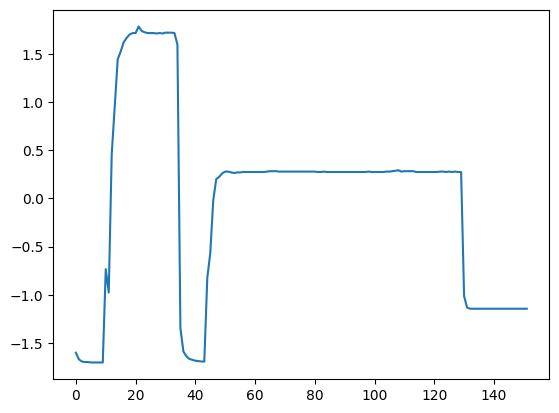

In [ ]:
import matplotlib.pyplot as plt

plt.plot(X_train[0,  :])